In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set tema visualisasi
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

# ==========================================
# 1. LOAD DATASET & DATA WRANGLING (CLEANING)
# ==========================================
df_pesanan = pd.read_csv("dataset_pesanan_ds.csv")

# Cek apakah pembelian_bahan.csv memiliki header dari phpMyAdmin
df_bahan_raw = pd.read_csv("pembelian_bahan.csv")
if "nama_bahan" not in df_bahan_raw.columns:
    df_bahan = pd.read_csv(
        "pembelian_bahan.csv",
        names=["id_pembelian", "id_user", "tgl_pembelian", "nama_bahan", "jumlah", "total_biaya"]
    )
else:
    df_bahan = df_bahan_raw.copy()

# Konversi tipe data tanggal
df_pesanan["tgl_pemesanan"] = pd.to_datetime(df_pesanan["tgl_pemesanan"])
df_pesanan["tgl_dibutuhkan"] = pd.to_datetime(df_pesanan["tgl_dibutuhkan"])
df_bahan["tgl_pembelian"] = pd.to_datetime(df_bahan["tgl_pembelian"])

# Tambah kolom fitur waktu untuk analisis & tim AI
df_pesanan["bulan"] = df_pesanan["tgl_pemesanan"].dt.to_period("M").astype(str)
df_pesanan["hari_pesan"] = df_pesanan["tgl_pemesanan"].dt.day_name()
df_pesanan["jam_pesan"] = df_pesanan["tgl_pemesanan"].dt.hour

print("=== RINGKASAN KUALITAS DATA PESANAN ===")
print("Jumlah Baris & Kolom :", df_pesanan.shape)
print("Missing Values       :\n", df_pesanan.isnull().sum()[df_pesanan.isnull().sum() > 0])
print("Jumlah Duplikat      :", df_pesanan.duplicated().sum())

print("\n=== RINGKASAN KUALITAS DATA BAHAN ===")
print("Jumlah Baris & Kolom :", df_bahan.shape)
print("Missing Values       :\n", df_bahan.isnull().sum()[df_bahan.isnull().sum() > 0])

# Export dataset bersih siap pakai untuk Tim AI (Christian & Yardan)
df_pesanan.to_csv("dataset_pesanan_clean_for_ai.csv", index=False)
print("\n[OK] File 'dataset_pesanan_clean_for_ai.csv' berhasil disimpan!")

=== RINGKASAN KUALITAS DATA PESANAN ===
Jumlah Baris & Kolom : (997, 16)
Missing Values       :
 Series([], dtype: int64)
Jumlah Duplikat      : 0

=== RINGKASAN KUALITAS DATA BAHAN ===
Jumlah Baris & Kolom : (74, 6)
Missing Values       :
 Series([], dtype: int64)

[OK] File 'dataset_pesanan_clean_for_ai.csv' berhasil disimpan!



=== PERFORMA PENJUALAN PER MENU ===
         nama_menu   kategori  total_porsi  total_omzet  frekuensi_order
        Snackbox 1  Snack Box         4485     22425000               81
 Snack Box Premium  Snack Box         3925     98125000               65
        Snackbox 5  Snack Box         3910     58650000               69
           Paket 2 Nasi Kotak         3750     56250000               68
           Paket 4 Nasi Kotak         3645     72900000               69
           Paket 1 Nasi Kotak         3510     42120000               65
Paket 2 Ayam Bumbu Nasi Kotak         3355     57035000               72
     Paket Spesial Nasi Kotak         3300     99000000               66
       Snack Box 4  Snack Box         3230     38760000               76
       Paket Bebek Nasi Kotak         3125    103125000               68
           Paket 5 Nasi Kotak         3015     75375000               65
       Snack Box 3  Snack Box         2985     29850000               63
       Snack B

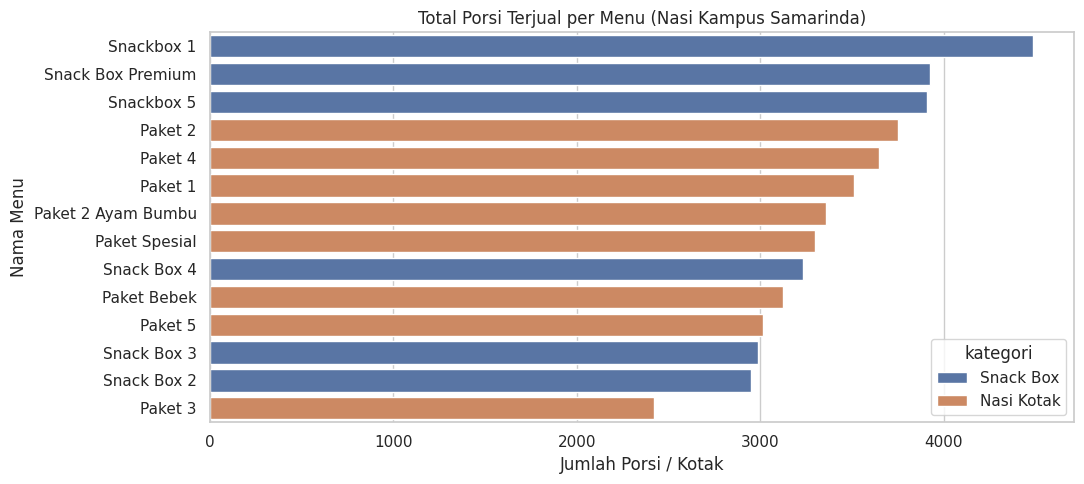


=== RINGKASAN KEUANGAN BULANAN ===
  bulan  total_omzet  total_biaya_bahan  estimasi_laba_kotor
2026-09    309200000         10342000.0          298858000.0
2026-10    297220000         10707000.0          286513000.0
2026-11    208985000          8602000.0          200383000.0


/tmp/ipykernel_929/1234915905.py:41: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_valid, x="label_prioritas_ai", order=["Normal", "Sedang", "Tinggi"], palette="viridis")


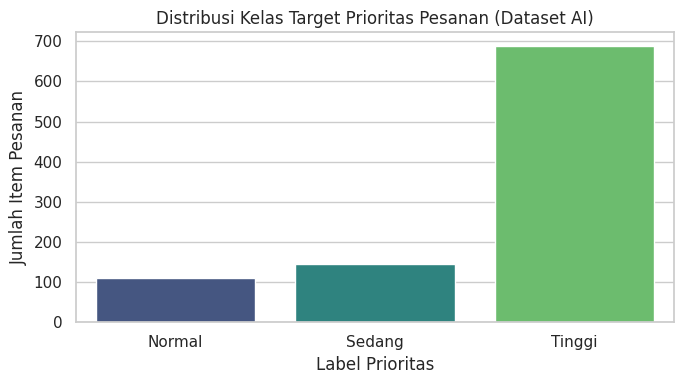


=== TOP 5 PELANGGAN REPEAT ORDER ===
               nama_pelanggan  jumlah_transaksi  total_belanja
          FKIP Unmul Hukum 46                 9       20135000
      Komunitas Loa Bakung 47                 9       14190000
Komunitas Sistem Informasi 62                 9        9985000
                Bapak Rina 17                 8       17290000
     Karang Taruna Ekonomi 88                 8       15930000


In [2]:
# Filter hanya transaksi valid (bukan dibatalkan) untuk hitung omzet riil
df_valid = df_pesanan[df_pesanan["status_pesanan"] != "dibatalkan"]

# ==========================================
# ANALISIS 1: MENU TERLARIS (PORSI & OMZET)
# ==========================================
top_menu = df_valid.groupby(["nama_menu", "kategori"]).agg(
    total_porsi=("jumlah", "sum"),
    total_omzet=("subtotal", "sum"),
    frekuensi_order=("id_pesanan", "nunique")
).reset_index().sort_values(by="total_porsi", ascending=False)

print("\n=== PERFORMA PENJUALAN PER MENU ===")
print(top_menu.to_string(index=False))

plt.figure(figsize=(11, 5))
sns.barplot(data=top_menu, x="total_porsi", y="nama_menu", hue="kategori", dodge=False)
plt.title("Total Porsi Terjual per Menu (Nasi Kampus Samarinda)")
plt.xlabel("Jumlah Porsi / Kotak")
plt.ylabel("Nama Menu")
plt.tight_layout()
plt.show()

# ==========================================
# ANALISIS 2: ARUS KAS BULANAN (OMZET VS BIAYA BAHAN)
# ==========================================
omzet_bulanan = df_valid.groupby("bulan")["subtotal"].sum().reset_index(name="total_omzet")
df_bahan["bulan"] = df_bahan["tgl_pembelian"].dt.to_period("M").astype(str)
biaya_bulanan = df_bahan.groupby("bulan")["total_biaya"].sum().reset_index(name="total_biaya_bahan")

keuangan = pd.merge(omzet_bulanan, biaya_bulanan, on="bulan", how="outer").fillna(0)
keuangan["estimasi_laba_kotor"] = keuangan["total_omzet"] - keuangan["total_biaya_bahan"]

print("\n=== RINGKASAN KEUANGAN BULANAN ===")
print(keuangan.to_string(index=False))

# ==========================================
# ANALISIS 3: DISTRIBUSI PRIORITAS PESANAN (UNTUK TIM AI)
# ==========================================
plt.figure(figsize=(7, 4))
sns.countplot(data=df_valid, x="label_prioritas_ai", order=["Normal", "Sedang", "Tinggi"], palette="viridis")
plt.title("Distribusi Kelas Target Prioritas Pesanan (Dataset AI)")
plt.xlabel("Label Prioritas")
plt.ylabel("Jumlah Item Pesanan")
plt.tight_layout()
plt.show()

# ==========================================
# ANALISIS 4: TOP 5 PELANGGAN REPEAT ORDER
# ==========================================
top_pelanggan = df_valid.groupby("nama_pelanggan").agg(
    jumlah_transaksi=("id_pesanan", "nunique"),
    total_belanja=("subtotal", "sum")
).reset_index().sort_values(by=["jumlah_transaksi", "total_belanja"], ascending=False).head(5)

print("\n=== TOP 5 PELANGGAN REPEAT ORDER ===")
print(top_pelanggan.to_string(index=False))